In [326]:
import sys 
print(sys.executable)
print(sys.version)

c:\this_pc\Masoom\data\PracticeProjects\1\ml-venv\Scripts\python.exe
3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]


In [327]:
import numpy as np
import pandas as pd

print('Numpy: ', np.__version__)
print('Pandas: ', pd.__version__)

Numpy:  2.5.2
Pandas:  3.0.5


In [328]:
#!pip install -r requirements.txt

In [329]:
import optuna
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier



In [330]:
df = pd.read_csv("Bank_Churn.csv")
df_copy = df.copy()


In [331]:
df.head()


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15571816,Ritchie,850,Spain,Female,70,5,0.00,1,1,1,705.18,0
1,15653521,Onuora,850,Germany,Female,40,7,104449.80,1,1,1,747.88,0
2,15657603,Finch,850,France,Female,35,6,81684.97,1,1,0,824.00,0
3,15676571,Bezrukova,850,France,Male,55,6,0.00,1,1,0,944.41,1
4,15644699,Crawford,850,France,Female,40,0,0.00,2,1,0,1099.95,0


In [332]:
df.shape


(10000, 13)

In [333]:
df.columns


Index(['CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age',
       'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='str')

In [334]:
df.dtypes


CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [335]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 1015.8 KB


In [336]:
df= df.drop(['CustomerId', 'Surname'], axis=1)

In [337]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


In [338]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [339]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [340]:
def plot_numerical(df, column):
    """
    Plots Histogram, KDE Plot, and Box Plot for a numerical column.

    Parameters:
        df (pd.DataFrame): The dataframe.
        column (str): Name of the numerical column.
    """

    plt.figure(figsize=(12, 5))

    # Histogram + KDE
    plt.subplot(1, 2, 1)
    sns.histplot(df[column], kde=True, bins=30, color="skyblue")
    plt.title(f"Histogram & KDE of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    # Box Plot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[column], color="lightgreen")
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

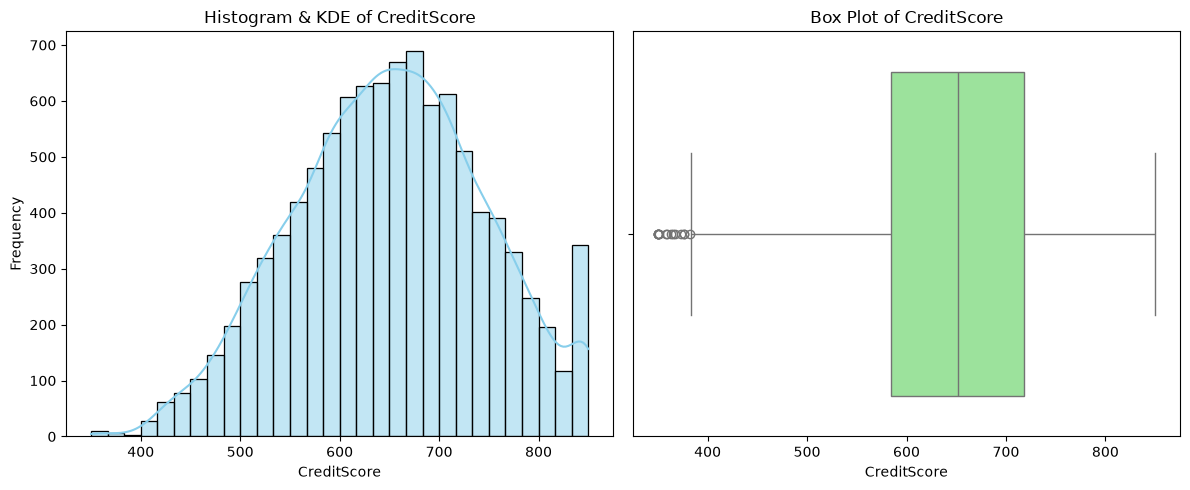

In [341]:

plot_numerical(df, 'CreditScore')

In [342]:
print(df["CreditScore"].skew())

-0.07160660820092675


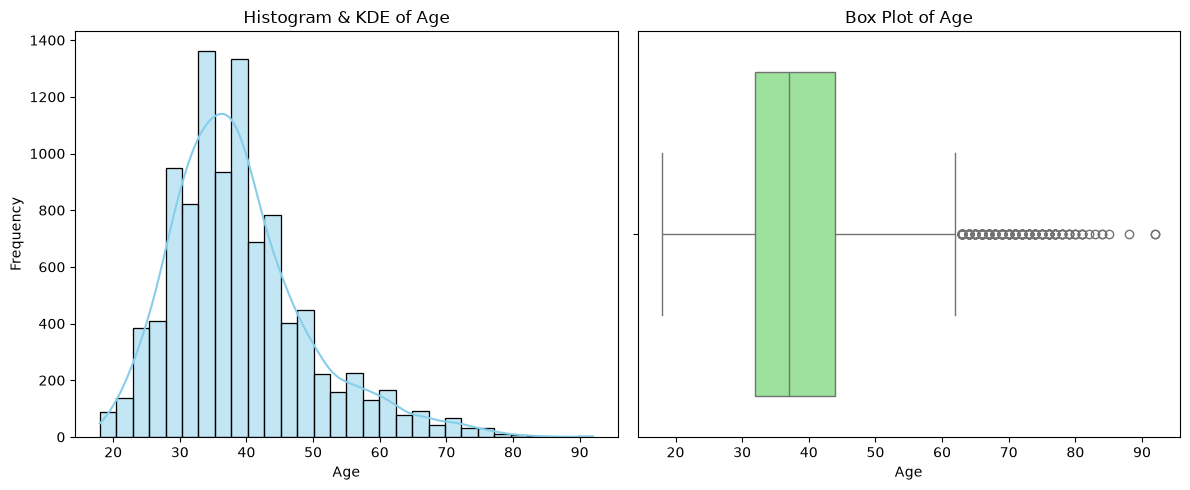

In [343]:
plot_numerical(df, 'Age')

In [344]:
print("Original:", df["Age"].skew())
print("Log:", np.log(df["Age"]).skew())
print("Sqrt:", np.sqrt(df["Age"]).skew())

Original: 1.0113202630234552
Log: 0.18202011255958703
Sqrt: 0.5934049767753408


In [345]:
df["LogAge"] = np.log1p(df["Age"])

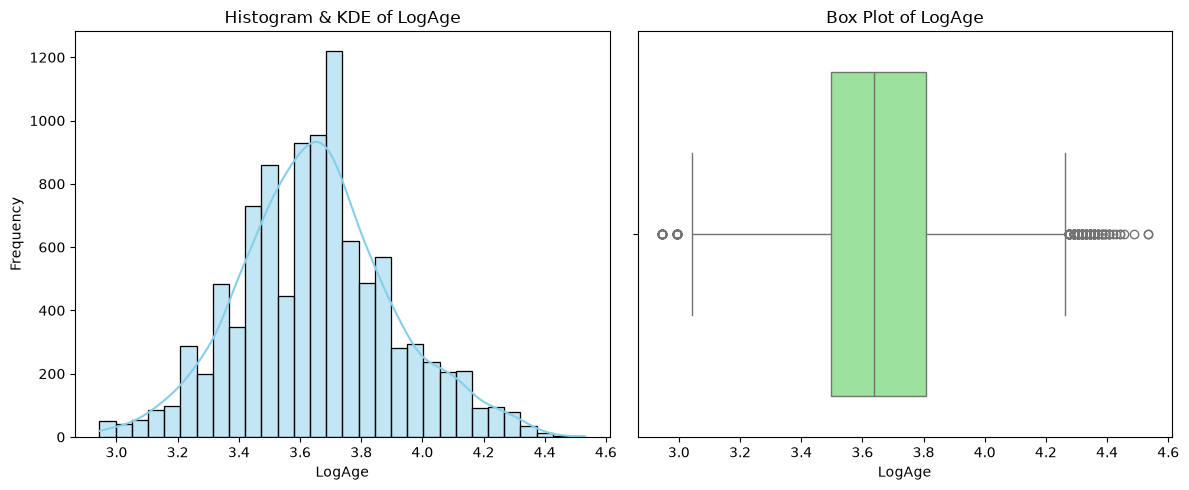

In [346]:
plot_numerical(df, 'LogAge')

In [347]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
 11  LogAge           10000 non-null  float64
dtypes: float64(3), int64(7), str(2)
memory usage: 937.6 KB


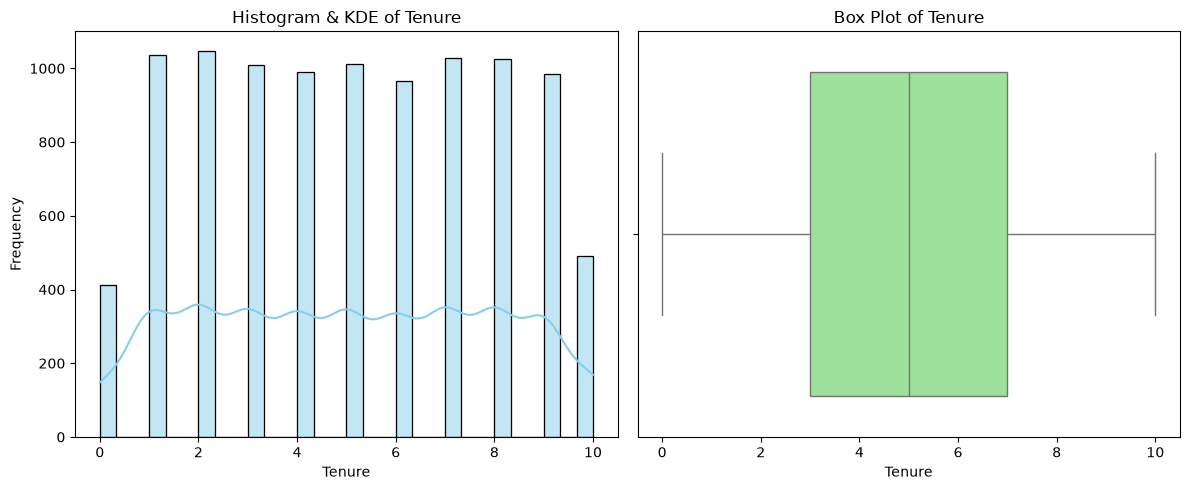

In [348]:
plot_numerical(df, 'Tenure')

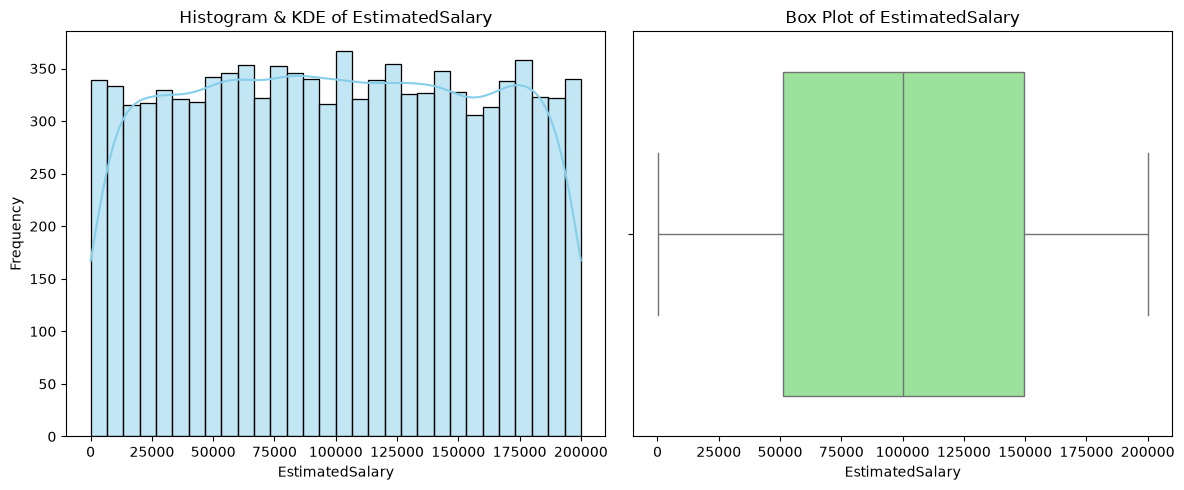

In [349]:
plot_numerical(df, 'EstimatedSalary')

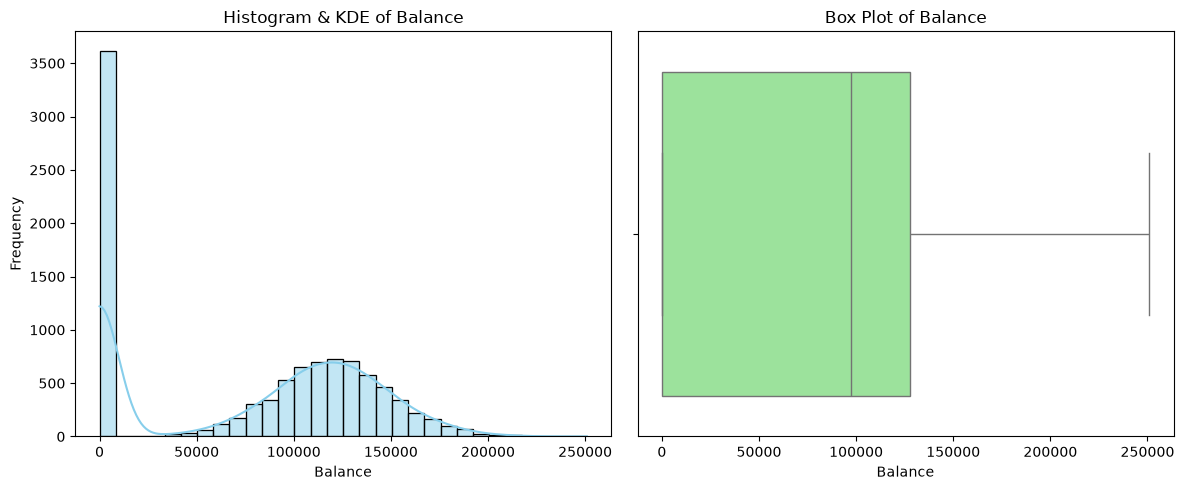

In [350]:
plot_numerical(df, 'Balance')

In [351]:
zero_count = (df["Balance"] == 0).sum()

zero_percentage = (df["Balance"] == 0).mean() * 100

print(zero_count)
print(f"{zero_percentage:.2f}%")

3617
36.17%


In [352]:
pd.crosstab(df["Balance"] == 0,
            df["Exited"],
            normalize="index")

Exited,0,1
Balance,,
False,0.759204,0.240796
True,0.861764,0.138236


<Axes: xlabel='Balance', ylabel='Count'>

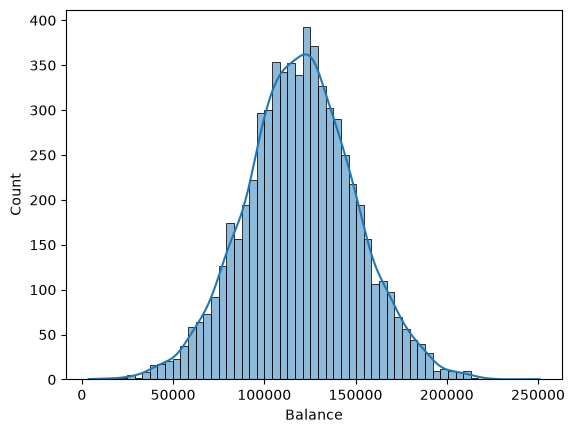

In [353]:
non_zero = df[df["Balance"] > 0]

sns.histplot(non_zero["Balance"], kde=True)

In [354]:
df["HasBalance"] = (df["Balance"] > 0).astype(int)

In [355]:
df.sample(5)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,LogAge,HasBalance
5074,650,France,Female,64,7,142028.36,1,1,0,32275.09,1,4.174387,1
7652,579,Spain,Male,33,1,0.00,2,1,1,54816.57,0,3.526361,0
5350,643,Spain,Female,35,6,0.00,2,1,1,41549.64,0,3.583519,0
3427,692,France,Female,42,2,0.00,2,1,0,145222.93,0,3.761200,0
456,817,Germany,Male,45,9,101207.75,1,0,0,88211.12,1,3.828641,1


In [356]:
def plot_categorical(df, column):
    """
    Plots Count Plot, Percentage Bar Plot, and Pie Chart
    for a categorical column.

    Parameters:
        df (pd.DataFrame): DataFrame
        column (str): Categorical column name
    """

    # Count and percentage
    counts = df[column].value_counts()
    percentages = df[column].value_counts(normalize=True) * 100

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # ---------------- Count Plot ---------------- #
    sns.countplot(
        data=df,
        x=column,
        order=counts.index,
        palette="Set2",
        ax=axes[0]
    )

    axes[0].set_title(f"Count Plot of {column}", fontsize=14, fontweight='bold')
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Count")

    # Add count labels
    for container in axes[0].containers:
        axes[0].bar_label(container)

    # ---------------- Percentage Bar Plot ---------------- #
    sns.barplot(
        x=percentages.index,
        y=percentages.values,
        palette="Set2",
        ax=axes[1]
    )

    axes[1].set_title(f"Percentage of {column}", fontsize=14, fontweight='bold')
    axes[1].set_xlabel(column)
    axes[1].set_ylabel("Percentage (%)")

    for i, v in enumerate(percentages.values):
        axes[1].text(i, v + 0.5, f"{v:.1f}%", ha='center', fontsize=10)

    # ---------------- Pie Chart ---------------- #
    axes[2].pie(
        counts.values,
        labels=counts.index,
        autopct="%1.1f%%",
        startangle=90
    )

    axes[2].set_title(f"Pie Chart of {column}", fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

C:\Users\masoo\AppData\Local\Temp\ipykernel_20136\2037373526.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\masoo\AppData\Local\Temp\ipykernel_20136\2037373526.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


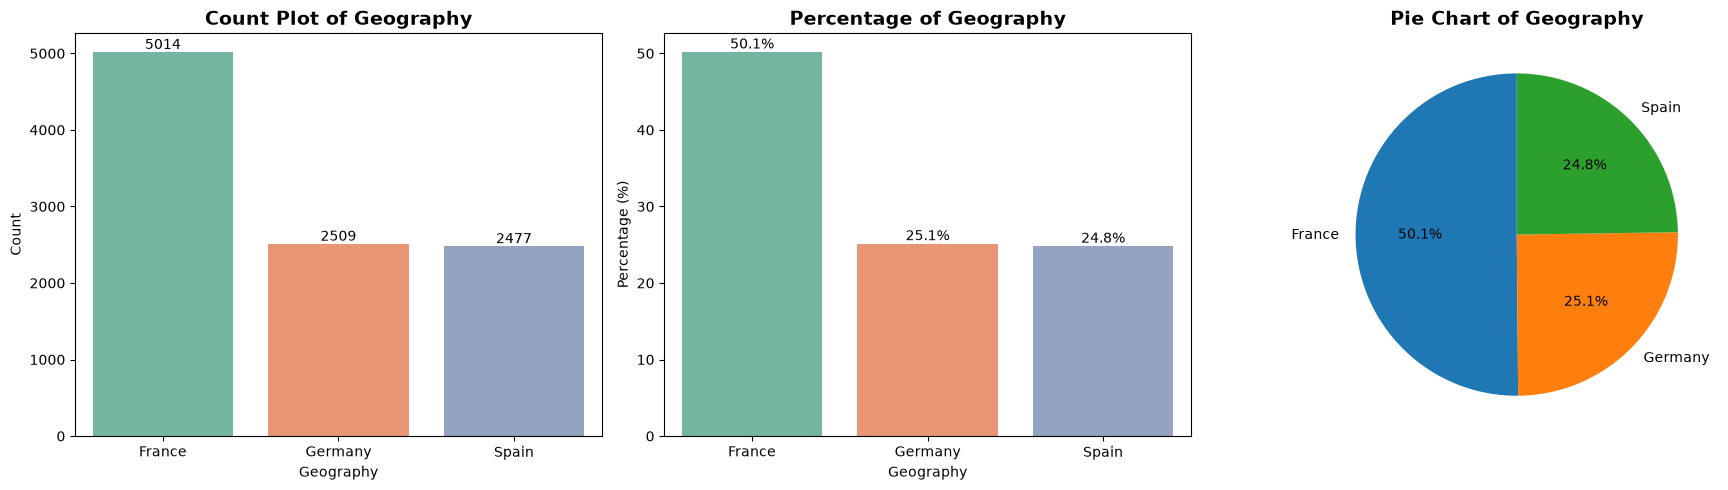

In [357]:
plot_categorical(df, 'Geography')

C:\Users\masoo\AppData\Local\Temp\ipykernel_20136\2037373526.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\masoo\AppData\Local\Temp\ipykernel_20136\2037373526.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


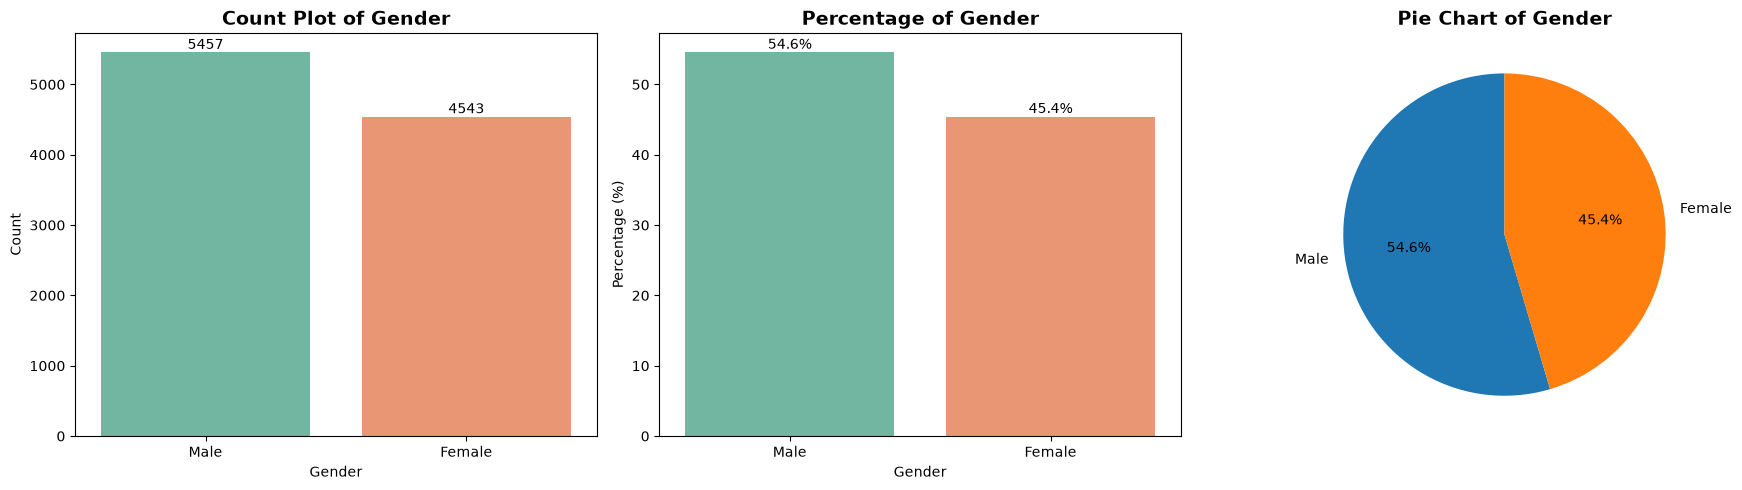

In [358]:
plot_categorical(df, 'Gender')

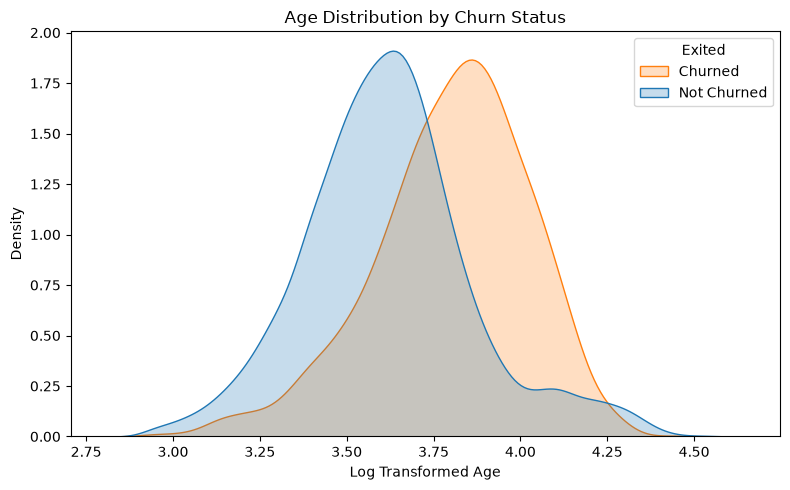

In [359]:
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x="LogAge",
    hue="Exited",
    fill=True,
    common_norm=False
)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Log Transformed Age")
plt.ylabel("Density")

plt.legend(
    title="Exited",
    labels=["Churned", "Not Churned"]
)

plt.tight_layout()
plt.show()

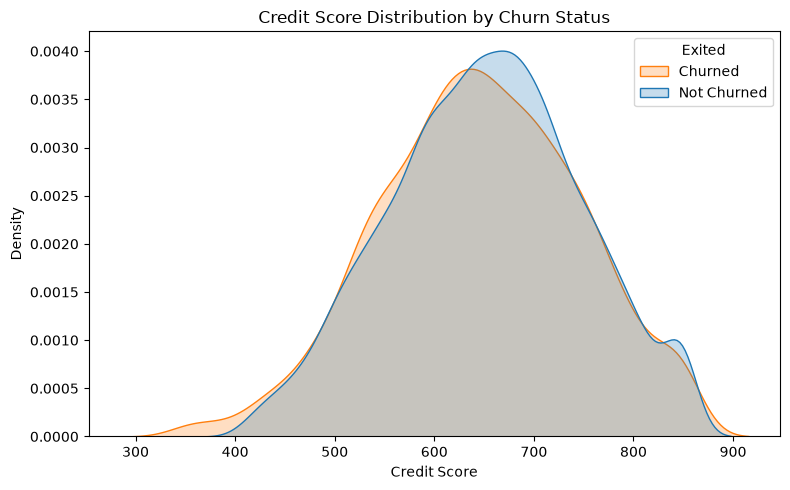

In [360]:
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x="CreditScore",
    hue="Exited",
    fill=True,
    common_norm=False
)

plt.title("Credit Score Distribution by Churn Status")
plt.xlabel("Credit Score")
plt.ylabel("Density")

plt.legend(
    title="Exited",
    labels=["Churned", "Not Churned"]
)

plt.tight_layout()
plt.show()

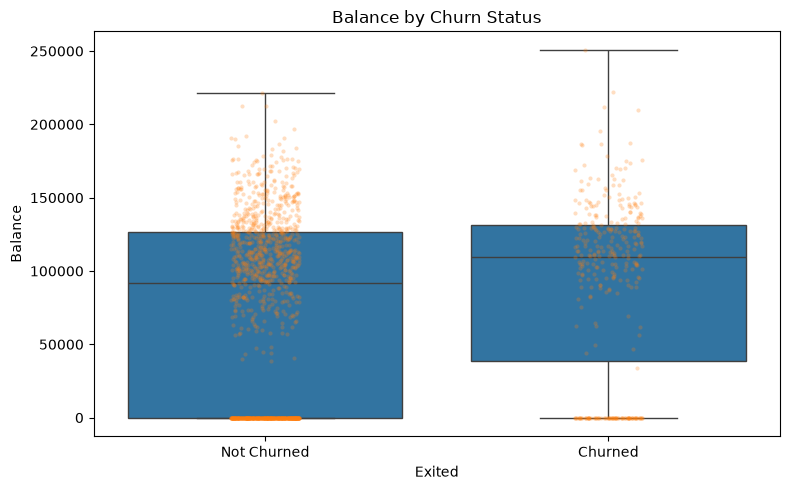

In [361]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

sns.stripplot(
    data=df.sample(min(1500, len(df))),
    x="Exited",
    y="Balance",
    alpha=0.25,
    size=3
)

plt.title("Balance by Churn Status")
plt.xlabel("Exited")
plt.ylabel("Balance")

plt.xticks(
    [0, 1],
    ["Not Churned", "Churned"]
)

plt.tight_layout()
plt.show()

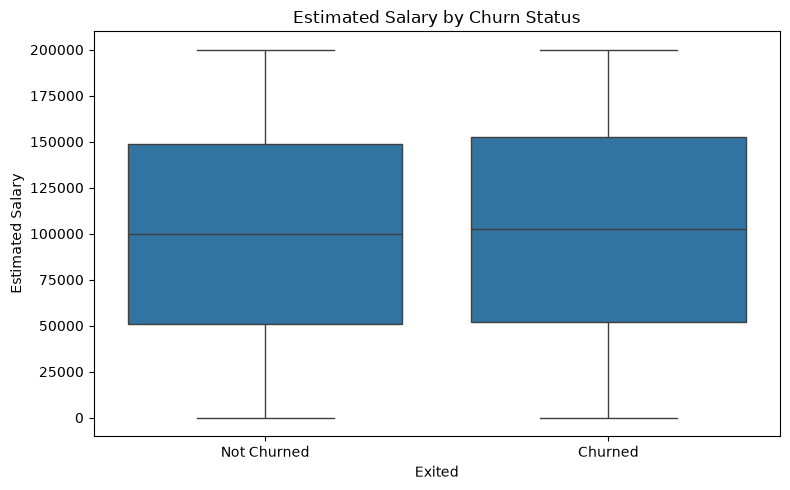

In [362]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="EstimatedSalary"
)

plt.title("Estimated Salary by Churn Status")
plt.xlabel("Exited")
plt.ylabel("Estimated Salary")

plt.xticks(
    [0, 1],
    ["Not Churned", "Churned"]
)

plt.tight_layout()
plt.show()

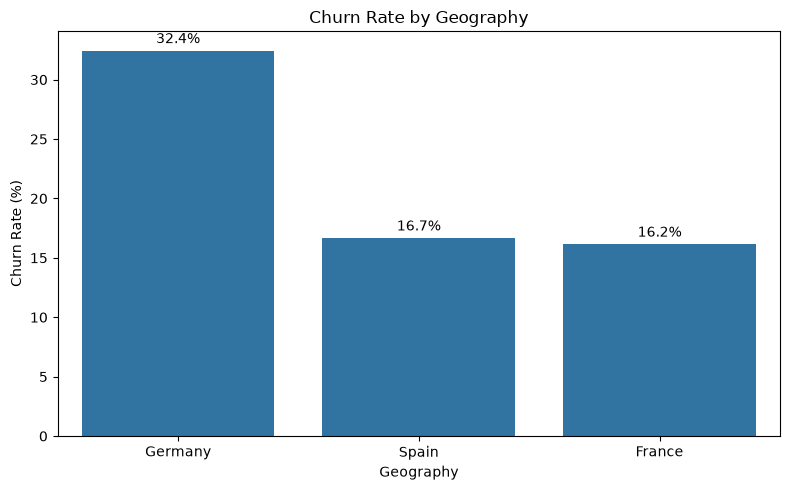

In [363]:
churn_rate = (
    df.groupby("Geography")["Exited"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

plt.title("Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

plt.tight_layout()
plt.show()

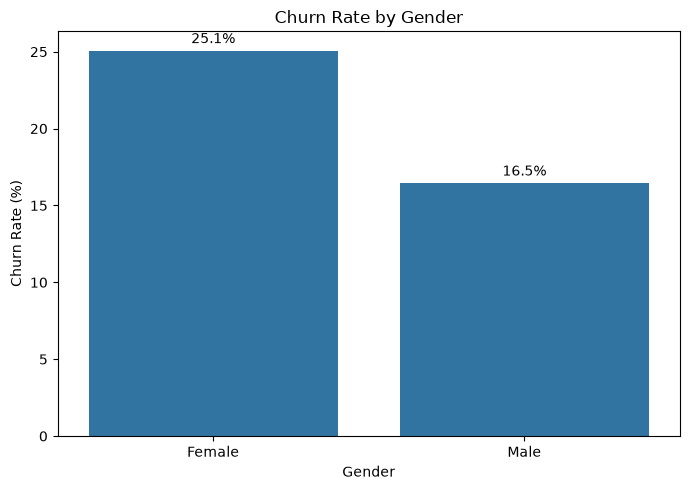

In [364]:
churn_rate = (
    df.groupby("Gender")["Exited"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

plt.tight_layout()
plt.show()

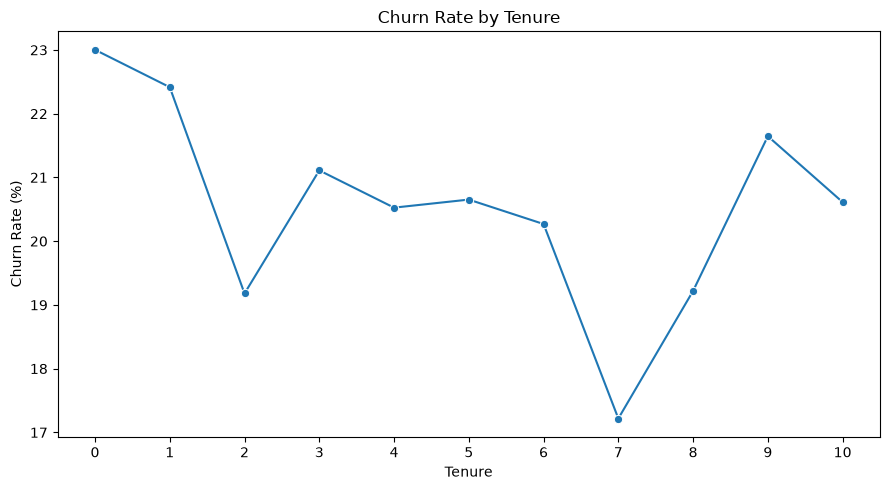

In [365]:
churn_rate = (
    df.groupby("Tenure")["Exited"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=churn_rate.index,
    y=churn_rate.values,
    marker="o"
)

plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")

plt.xticks(churn_rate.index)

plt.tight_layout()
plt.show()

In [366]:
tenure_summary = (
    df.groupby('Tenure')['Exited']
      .agg(
          Total_Customers='count',
          Churned_Customers='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

tenure_summary['Churn_Rate'] = tenure_summary['Churn_Rate'] * 100

tenure_summary

,Tenure,Total_Customers,Churned_Customers,Churn_Rate
0,0,413,95,23.002421
1,1,1035,232,22.415459
2,2,1048,201,19.179389
3,3,1009,213,21.110010
4,4,989,203,20.525784
5,5,1012,209,20.652174
6,6,967,196,20.268873
7,7,1028,177,17.217899
8,8,1025,197,19.219512
9,9,984,213,21.646341


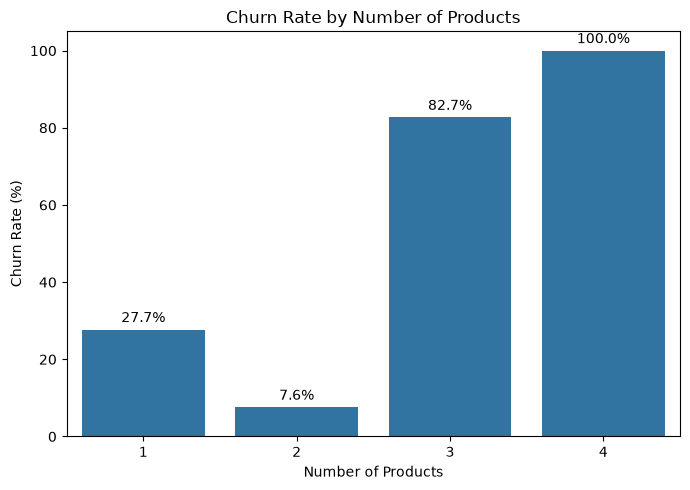

In [367]:
churn_rate = (
    df.groupby("NumOfProducts")["Exited"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

plt.tight_layout()
plt.show()

In [368]:
product_summary = (
    df.groupby('NumOfProducts')['Exited']
      .agg(
          Total_Customers='count',
          Churned_Customers='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

product_summary['Churn_Rate'] = product_summary['Churn_Rate'] * 100

product_summary

,NumOfProducts,Total_Customers,Churned_Customers,Churn_Rate
0,1,5084,1409,27.714398
1,2,4590,348,7.581699
2,3,266,220,82.706767
3,4,60,60,100.000000


In [369]:
df['NumOfProducts'].value_counts().sort_index()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [370]:
df[df['NumOfProducts'].isin([3, 4])].describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,LogAge,HasBalance
count,326.000000,326.000000,326.000000,326.000000,326.000000,326.000000,326.000000,326.000000,326.000000,326.000000,326.000000
mean,649.113497,43.653374,5.058282,78821.789571,3.184049,0.708589,0.435583,104400.141503,0.858896,3.772469,0.656442
std,96.200413,10.148108,2.889713,62283.191084,0.388120,0.455111,0.496595,55759.764947,0.348664,0.233394,0.475626
min,358.000000,21.000000,0.000000,0.000000,3.000000,0.000000,0.000000,3440.470000,0.000000,3.091042,0.000000
25%,587.250000,37.000000,3.000000,0.000000,3.000000,0.000000,0.000000,64344.800000,1.000000,3.637586,0.000000
50%,650.000000,43.000000,5.000000,101628.675000,3.000000,1.000000,0.000000,103874.670000,1.000000,3.784190,1.000000
75%,711.000000,50.000000,8.000000,128743.610000,3.000000,1.000000,1.000000,151150.967500,1.000000,3.931826,1.000000
max,850.000000,77.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199357.240000,1.000000,4.356709,1.000000


In [371]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,LogAge,HasBalance
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700,3.654701,0.638300
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769,0.251651,0.480517
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,2.944439,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,3.496508,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,3.637586,1.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,3.806662,1.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,4.532599,1.000000


In [372]:
product_4 = df[df['NumOfProducts'] == 4]

summary = {
    'Total Customers': len(product_4),
    'Average Age': product_4['Age'].mean(),
    'Median Age': product_4['Age'].median(),
    'Germany %': (product_4['Geography'] == 'Germany').mean() * 100,
    'Inactive %': (product_4['IsActiveMember'] == 0).mean() * 100
}

pd.Series(summary)

Total Customers    60.000000
Average Age        45.683333
Median Age         45.000000
Germany %          40.000000
Inactive %         51.666667
dtype: float64

In [373]:
product_4 = df[df['NumOfProducts'] == 4]

total_4_product = len(product_4)

german_4_product = (product_4['Geography'] == 'Germany').sum()

german_percentage = german_4_product / total_4_product * 100

print(f"Total 4-product customers : {total_4_product}")
print(f"German 4-product customers: {german_4_product}")
print(f"Percentage from Germany   : {german_percentage:.2f}%")

Total 4-product customers : 60
German 4-product customers: 24
Percentage from Germany   : 40.00%


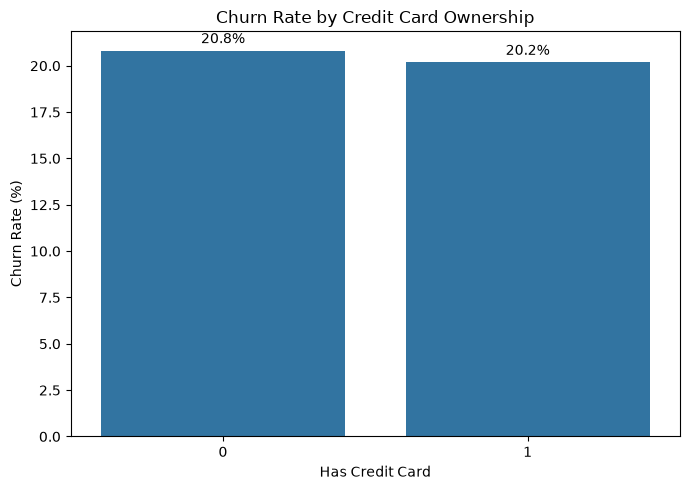

In [374]:
churn_rate = (
    df.groupby("HasCrCard")["Exited"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

plt.title("Churn Rate by Credit Card Ownership")
plt.xlabel("Has Credit Card")
plt.ylabel("Churn Rate (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

plt.tight_layout()
plt.show()

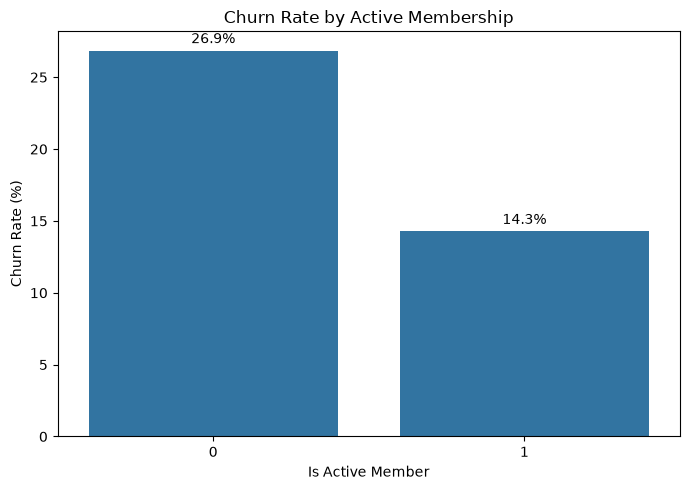

In [375]:
churn_rate = (
    df.groupby("IsActiveMember")["Exited"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)

plt.title("Churn Rate by Active Membership")
plt.xlabel("Is Active Member")
plt.ylabel("Churn Rate (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

plt.tight_layout()
plt.show()

In [376]:
df['BalanceSegment'] = np.select(
    [
        df['Balance'].eq(0),
        df['Balance'].between(0.01, 10000),
        df['Balance'].between(10000.01, 100000),
        df['Balance'].between(100000.01, 200000),
        df['Balance'].between(200000.01, 300000)
    ],
    [
        '0',
        '>0–10K',
        '>10K–100K',
        '>100K–200K',
        '>200K–300K'
    ],
    default='>300K'
)

In [377]:
balance_churn_summary = (
    df.groupby('BalanceSegment', observed=True)['Exited']
    .agg(
        Customers='count',
        Churned='sum',
        Churn_Rate='mean'
    )
    .reset_index()
)

balance_churn_summary['Churn_Rate'] *= 100

balance_churn_summary

,BalanceSegment,Customers,Churned,Churn_Rate
0,0,3617,500,13.823611
1,>0–10K,1,1,100.000000
2,>100K–200K,4765,1192,25.015740
3,>10K–100K,1583,325,20.530638
4,>200K–300K,34,19,55.882353


In [378]:
df['AgeGroup'] = np.select(
    [
            df['Age'].between(0, 30),
            df['Age'].between(31, 40),
            df['Age'].between(41, 50),
            df['Age'].between(51, 60),
            df['Age'] > 60
    ],
    [      '≤30', 
           '31–40', 
           '41–50', 
           '51–60', 
           '60+'
    ], 
    default='Unknown'

) 


In [379]:
age_churn_summary = (
    df.groupby('AgeGroup', observed=True)['Exited']
    .agg(
        Customers='count',
        Churned='sum',
        Churn_Rate='mean'
    )
    .reset_index()
)

age_churn_summary['Churn_Rate'] *= 100

age_churn_summary

,AgeGroup,Customers,Churned,Churn_Rate
0,31–40,4451,538,12.087171
1,41–50,2320,788,33.965517
2,51–60,797,448,56.210790
3,60+,464,115,24.784483
4,≤30,1968,148,7.520325


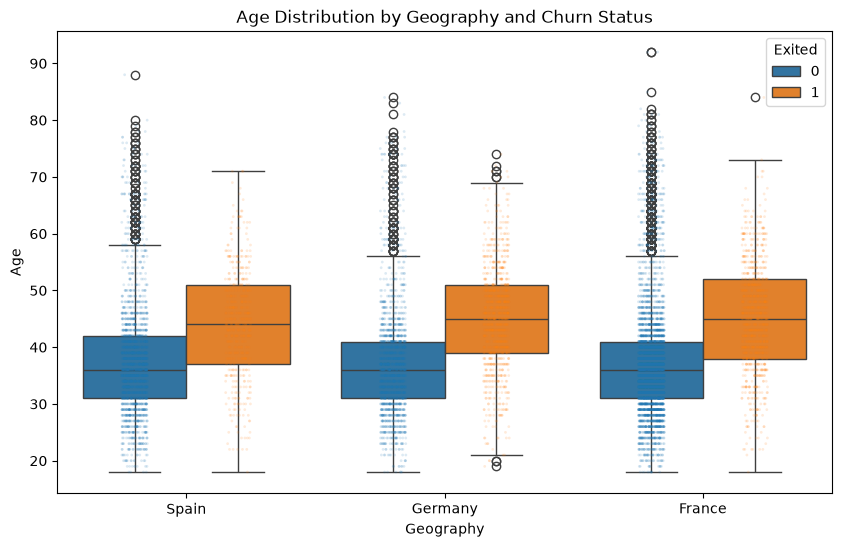

In [380]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Geography',
    y='Age',
    hue='Exited'
)

sns.stripplot(
    data=df,
    x='Geography',
    y='Age',
    hue='Exited',
    dodge=True,
    alpha=0.15,
    size=2,
    legend=False
)

plt.title('Age Distribution by Geography and Churn Status')
plt.xlabel('Geography')
plt.ylabel('Age')
plt.show()

In [381]:
age_geo_churn = (
    df.groupby(
        ['Geography', 'AgeGroup'],
        observed=True
    )['Exited']
    .agg(
        Customers='count',
        Churned='sum',
        Churn_Rate='mean'
    )
    .reset_index()
)

age_geo_churn['Churn_Rate'] *= 100

age_geo_churn

,Geography,AgeGroup,Customers,Churned,Churn_Rate
0,France,31–40,2311,220,9.519688
1,France,41–50,1067,300,28.116214
2,France,51–60,367,193,52.588556
3,France,60+,231,46,19.913420
4,France,≤30,1038,51,4.913295
5,Germany,31–40,1022,214,20.939335
6,Germany,41–50,678,331,48.820059
7,Germany,51–60,243,169,69.547325
8,Germany,60+,113,44,38.938053
9,Germany,≤30,453,56,12.362031


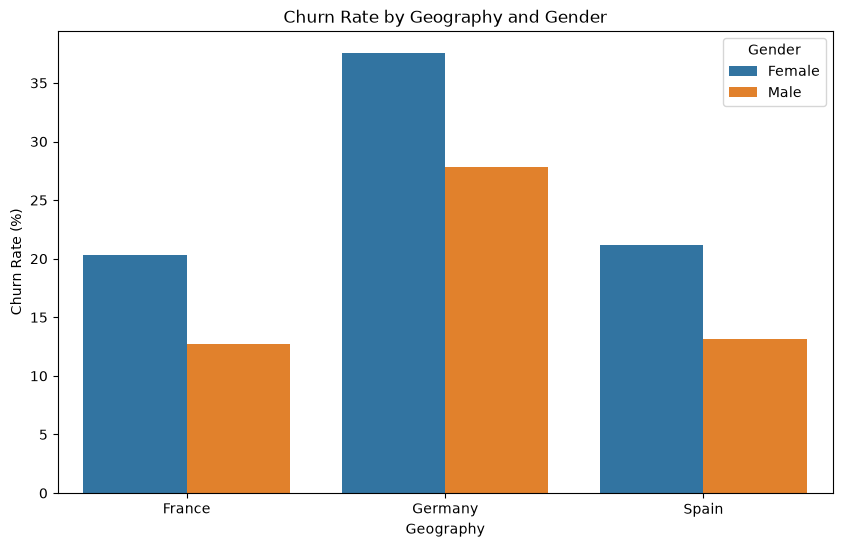

In [382]:
gender_geo = (
    df.groupby(['Geography', 'Gender'])['Exited']
      .mean()
      .reset_index()
)

gender_geo['Exited'] *= 100

plt.figure(figsize=(10, 6))

sns.barplot(
    data=gender_geo,
    x='Geography',
    y='Exited',
    hue='Gender'
)

plt.title('Churn Rate by Geography and Gender')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.legend(title='Gender')
plt.show()

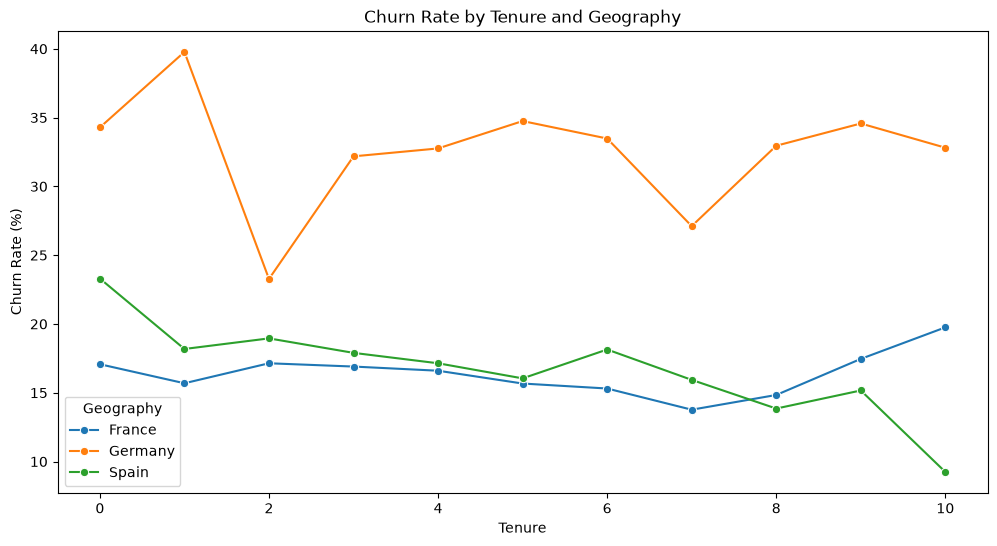

In [383]:
tenure_geo_churn = (
    df.groupby(['Geography', 'Tenure'])['Exited']
      .mean()
      .reset_index()
)

tenure_geo_churn['Exited'] *= 100

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=tenure_geo_churn,
    x='Tenure',
    y='Exited',
    hue='Geography',
    marker='o'
)

plt.title('Churn Rate by Tenure and Geography')
tenure_geo_churn = (
    df.groupby(['Geography', 'Tenure'])['Exited']
      .mean()
      .reset_index()
)


plt.title('Churn Rate by Tenure and Geography')
plt.xlabel('Tenure')
plt.ylabel('Churn Rate (%)')
plt.show()

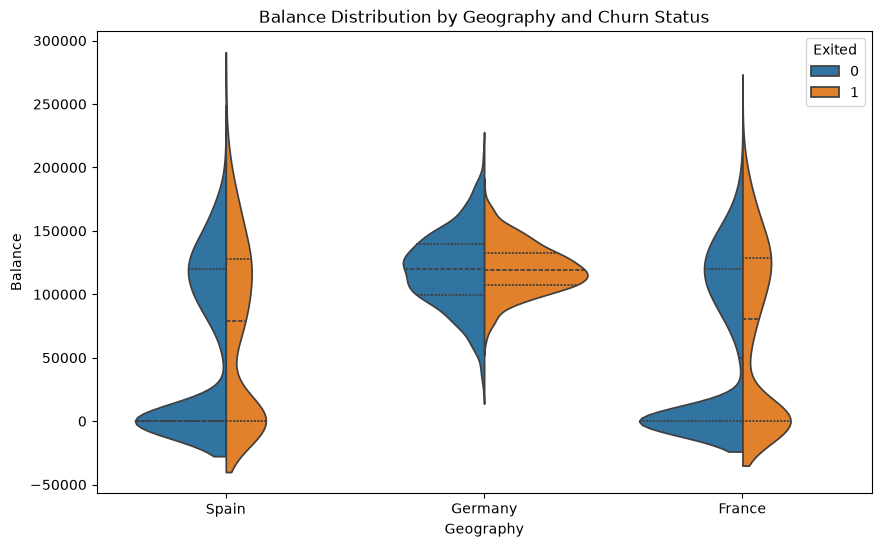

In [384]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='Geography',
    y='Balance',
    hue='Exited',
    split=True,
    inner='quartile'
)

plt.title('Balance Distribution by Geography and Churn Status')
plt.xlabel('Geography')
plt.ylabel('Balance')
plt.show()

In [385]:
balance_geo = (
    df.groupby(
        ['Geography', 'BalanceSegment'],
        observed=True
    )['Exited']
    .agg(
        Customers='count',
        Churned='sum',
        Churn_Rate='mean'
    )
    .reset_index()
)

balance_geo['Churn_Rate'] *= 100

balance_geo

,Geography,BalanceSegment,Customers,Churned,Churn_Rate
0,France,0,2418,337,13.937138
1,France,>0–10K,1,1,100.000000
2,France,>100K–200K,1892,333,17.600423
3,France,>10K–100K,687,129,18.777293
4,France,>200K–300K,16,10,62.500000
5,Germany,>100K–200K,1960,706,36.020408
6,Germany,>10K–100K,543,108,19.889503
7,Germany,>200K–300K,6,0,0.000000
8,Spain,0,1199,163,13.594662
9,Spain,>100K–200K,913,153,16.757941


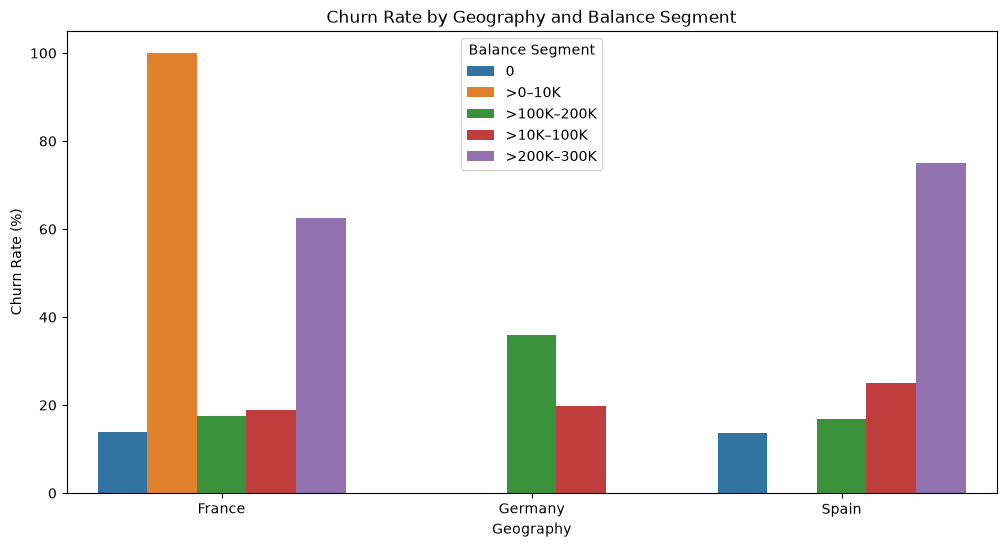

In [386]:
balance_geo = (
    df.groupby(['Geography', 'BalanceSegment'], observed=True)['Exited']
      .mean()
      .reset_index()
)

balance_geo['Exited'] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=balance_geo,
    x='Geography',
    y='Exited',
    hue='BalanceSegment'
)

plt.title('Churn Rate by Geography and Balance Segment')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.legend(title='Balance Segment')
plt.show()

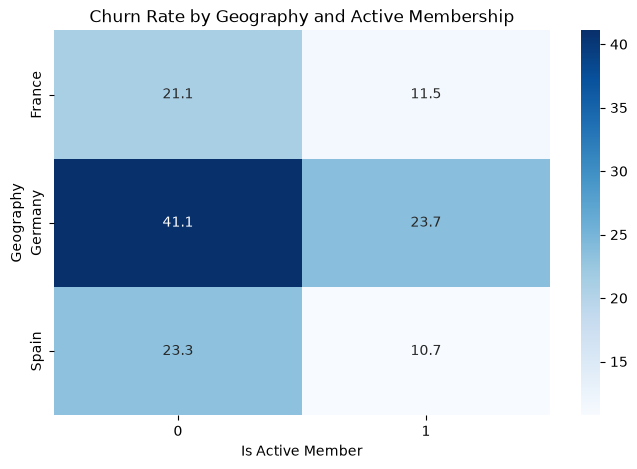

In [387]:
geo_active = (
    df.groupby(['Geography', 'IsActiveMember'])['Exited']
      .mean()
      .unstack()
)

geo_active *= 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    geo_active,
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.title('Churn Rate by Geography and Active Membership')
plt.xlabel('Is Active Member')
plt.ylabel('Geography')
plt.show()

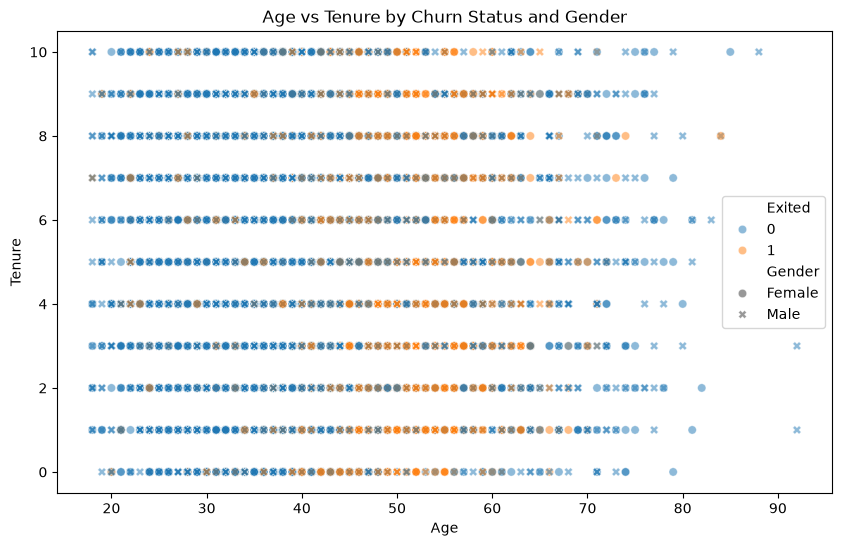

In [388]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Tenure',
    hue='Exited',
    style='Gender',
    alpha=0.5
)

plt.title('Age vs Tenure by Churn Status and Gender')
plt.xlabel('Age')
plt.ylabel('Tenure')
plt.show()

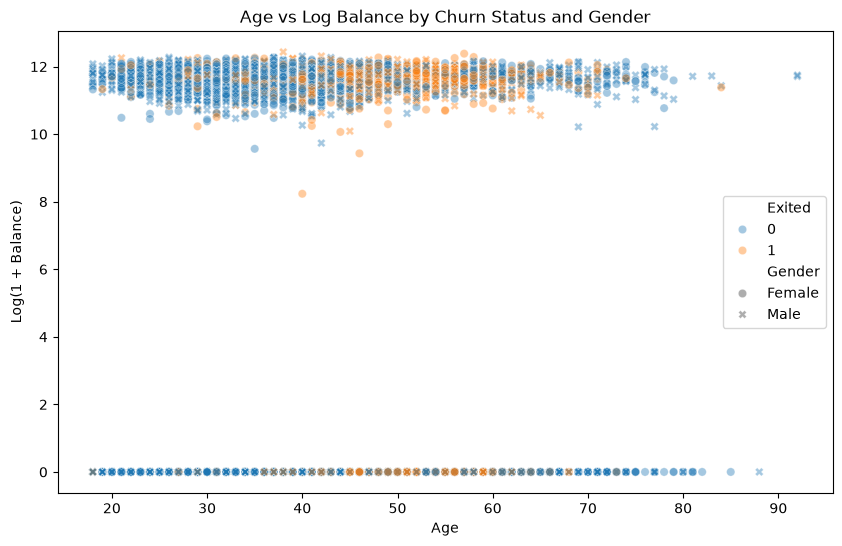

In [389]:
df['LogBalance'] = np.log1p(df['Balance'])

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='LogBalance',
    hue='Exited',
    style='Gender',
    alpha=0.4
)

plt.title('Age vs Log Balance by Churn Status and Gender')
plt.xlabel('Age')
plt.ylabel('Log(1 + Balance)')
plt.show()

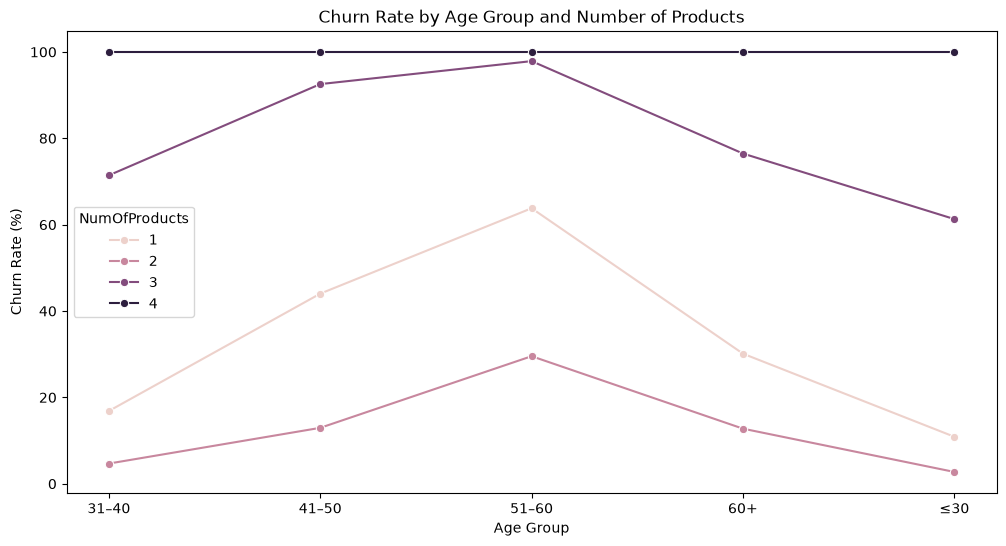

In [390]:
age_products = (
    df.groupby(
        ['AgeGroup', 'NumOfProducts'],
        observed=True
    )['Exited']
    .mean()
    .reset_index()
)

age_products['Exited'] *= 100

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=age_products,
    x='AgeGroup',
    y='Exited',
    hue='NumOfProducts',
    marker='o'
)

plt.title('Churn Rate by Age Group and Number of Products')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')
plt.show()

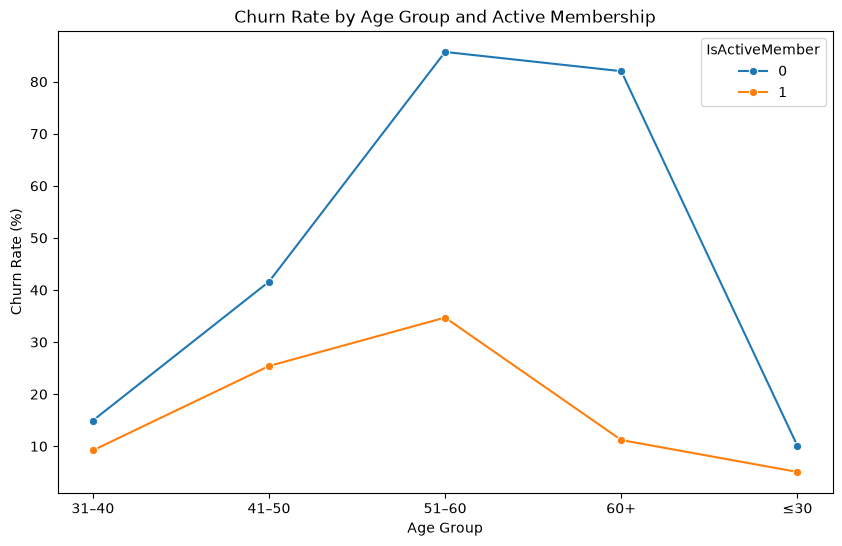

In [391]:
age_active = (
    df.groupby(
        ['AgeGroup', 'IsActiveMember'],
        observed=True
    )['Exited']
    .mean()
    .reset_index()
)

age_active['Exited'] *= 100

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=age_active,
    x='AgeGroup',
    y='Exited',
    hue='IsActiveMember',
    marker='o'
)

plt.title('Churn Rate by Age Group and Active Membership')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')
plt.show()

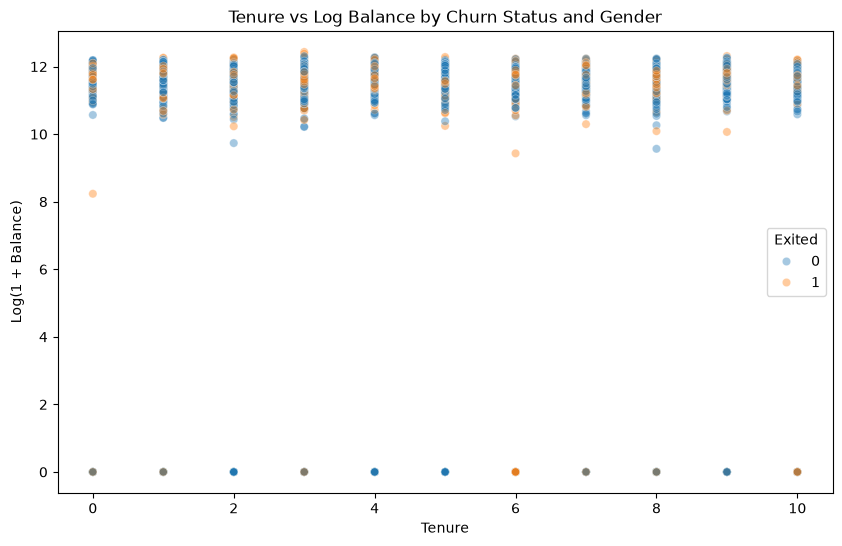

In [392]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Tenure',
    y='LogBalance',
    hue='Exited',
    alpha=0.4
)

plt.title('Tenure vs Log Balance by Churn Status and Gender')
plt.xlabel('Tenure')
plt.ylabel('Log(1 + Balance)')
plt.show()

In [393]:
tenure_balance_churn = (
    df.groupby(['Tenure', 'Exited'])['Balance']
      .agg(
          Customers='count',
          Mean_Balance='mean',
          Median_Balance='median',
          Std_Balance='std'
      )
      .reset_index()
)

tenure_balance_churn

,Tenure,Exited,Customers,Mean_Balance,Median_Balance,Std_Balance
0,0,0,318,75046.463270,92909.165,62471.316176
1,0,1,95,96054.892316,113688.630,57059.802514
2,1,0,803,75293.938095,94773.110,61620.748151
3,1,1,232,89843.924052,107935.065,57694.737313
4,2,0,847,75055.653211,94464.810,62909.316584
5,2,1,201,84357.165522,106344.950,63935.233615
6,3,0,796,74327.391508,96135.370,63128.793364
7,3,1,213,90152.435587,108924.330,56068.072351
8,4,0,786,70464.682646,88754.655,61931.896700
9,4,1,203,87977.833350,108825.340,58234.660837


In [394]:
tenure_balance_gender = (
    df.groupby(['Tenure', 'Gender'])['Balance']
      .agg(
          Customers='count',
          Mean_Balance='mean',
          Median_Balance='median'
      )
      .reset_index()
)

tenure_balance_gender

,Tenure,Gender,Customers,Mean_Balance,Median_Balance
0,0,Female,204,79024.705784,99497.190
1,0,Male,209,80712.679952,101016.530
2,1,Female,478,80018.655042,102191.965
3,1,Male,557,77299.650916,97700.020
4,2,Female,480,76965.144708,95000.075
5,2,Male,568,76733.554718,99848.930
6,3,Female,469,77197.938124,99705.690
7,3,Male,540,78076.369333,98310.570
8,4,Female,442,69906.732760,88558.825
9,4,Male,547,77414.926600,98141.570


In [395]:
tenure_balance_segment = (
    df.groupby(
        ['Tenure', 'BalanceSegment']
    )['Exited']
    .agg(
        Customers='count',
        Churned='sum',
        Churn_Rate='mean'
    )
    .reset_index()
)

tenure_balance_segment['Churn_Rate'] *= 100

tenure_balance_segment

,Tenure,BalanceSegment,Customers,Churned,Churn_Rate
0,0,0,137,20,14.598540
1,0,>0–10K,1,1,100.000000
2,0,>100K–200K,206,62,30.097087
3,0,>10K–100K,69,12,17.391304
4,1,0,349,59,16.905444
5,1,>100K–200K,510,139,27.254902
6,1,>10K–100K,173,32,18.497110
7,1,>200K–300K,3,2,66.666667
8,2,0,382,64,16.753927
9,2,>100K–200K,505,108,21.386139


In [396]:
tenure_balance_segment = (
    df.groupby(
        ['Tenure', 'BalanceSegment']
    )['Exited']
    .agg(
        Customers='count',
        Churned='sum',
        Churn_Rate='mean'
    )
    .reset_index()
)

tenure_balance_segment['Churn_Rate'] *= 100

tenure_balance_segment

,Tenure,BalanceSegment,Customers,Churned,Churn_Rate
0,0,0,137,20,14.598540
1,0,>0–10K,1,1,100.000000
2,0,>100K–200K,206,62,30.097087
3,0,>10K–100K,69,12,17.391304
4,1,0,349,59,16.905444
5,1,>100K–200K,510,139,27.254902
6,1,>10K–100K,173,32,18.497110
7,1,>200K–300K,3,2,66.666667
8,2,0,382,64,16.753927
9,2,>100K–200K,505,108,21.386139


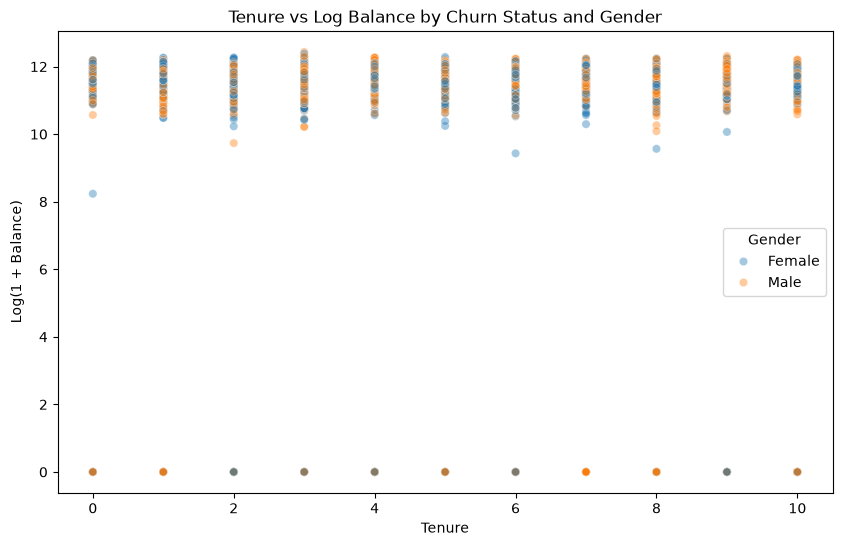

In [397]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Tenure',
    y='LogBalance',
    hue='Gender',
    alpha=0.4
)

plt.title('Tenure vs Log Balance by Churn Status and Gender')
plt.xlabel('Tenure')
plt.ylabel('Log(1 + Balance)')
plt.show()

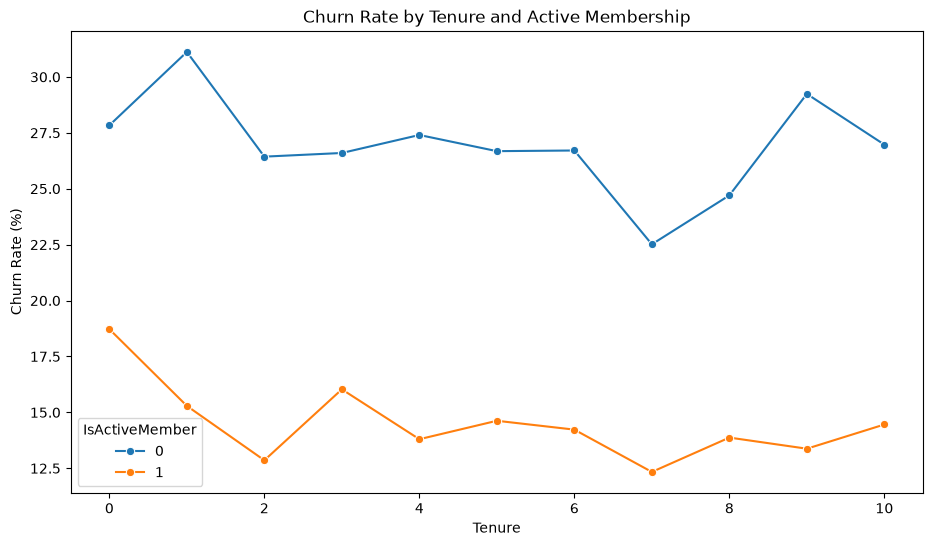

In [398]:
tenure_active = (
    df.groupby(['Tenure', 'IsActiveMember'])['Exited']
      .mean()
      .reset_index()
)

tenure_active['Exited'] *= 100

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=tenure_active,
    x='Tenure',
    y='Exited',
    hue='IsActiveMember',
    marker='o'
)

plt.title('Churn Rate by Tenure and Active Membership')
plt.xlabel('Tenure')
plt.ylabel('Churn Rate (%)')
plt.show()

In [399]:
df['Tenure_Active'] = (
    df['Tenure'].astype(str) + '_' +
    df['IsActiveMember'].astype(str)
)

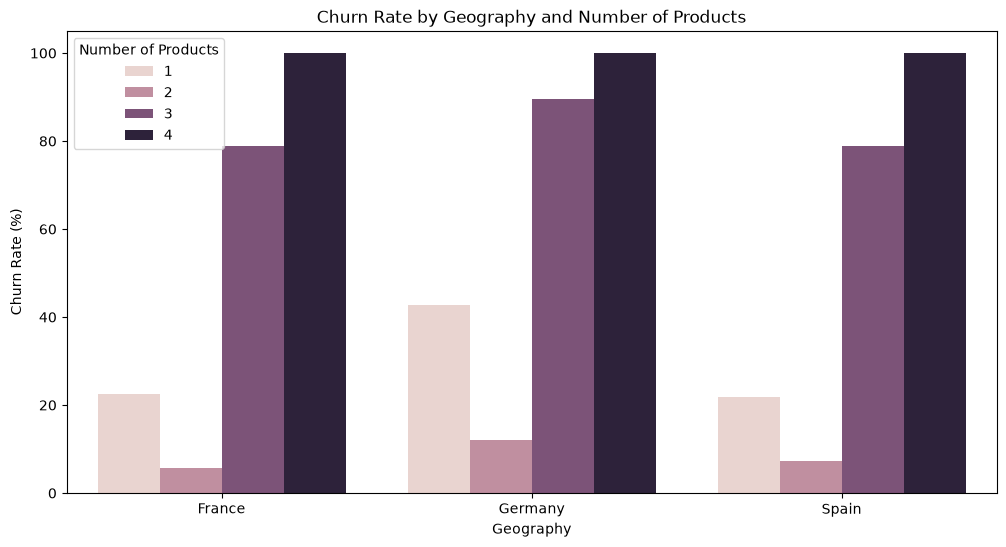

In [400]:
geo_products = (
    df.groupby(['Geography', 'NumOfProducts'])['Exited']
      .mean()
      .reset_index()
)

geo_products['Exited'] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=geo_products,
    x='Geography',
    y='Exited',
    hue='NumOfProducts'
)

plt.title('Churn Rate by Geography and Number of Products')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.legend(title='Number of Products')
plt.show()

In [401]:
age_gender_churn = (
    df.groupby(['AgeGroup', 'Gender'])['Exited']
      .agg(
          Customers='count',
          Churned='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

age_gender_churn['Churn_Rate'] *= 100

age_gender_churn

,AgeGroup,Gender,Customers,Churned,Churn_Rate
0,31–40,Female,1959,305,15.569168
1,31–40,Male,2492,233,9.349920
2,41–50,Female,1100,428,38.909091
3,41–50,Male,1220,360,29.508197
4,51–60,Female,391,255,65.217391
5,51–60,Male,406,193,47.536946
6,60+,Female,213,64,30.046948
7,60+,Male,251,51,20.318725
8,≤30,Female,880,87,9.886364
9,≤30,Male,1088,61,5.606618


In [402]:
products_active_churn = (
    df.groupby(['NumOfProducts', 'IsActiveMember'])['Exited']
      .agg(
          Customers='count',
          Churned='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

products_active_churn['Churn_Rate'] *= 100

products_active_churn

,NumOfProducts,IsActiveMember,Customers,Churned,Churn_Rate
0,1,0,2521,924,36.652122
1,1,1,2563,485,18.923137
2,2,0,2144,212,9.888060
3,2,1,2446,136,5.560098
4,3,0,153,135,88.235294
5,3,1,113,85,75.221239
6,4,0,31,31,100.000000
7,4,1,29,29,100.000000


In [403]:
balance_active_churn = (
    df.groupby(['BalanceSegment', 'IsActiveMember'])['Exited']
      .agg(
          Customers='count',
          Churned='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

balance_active_churn['Churn_Rate'] *= 100

balance_active_churn

,BalanceSegment,IsActiveMember,Customers,Churned,Churn_Rate
0,0,0,1744,320,18.348624
1,0,1,1873,180,9.610251
2,>0–10K,0,1,1,100.000000
3,>100K–200K,0,2337,764,32.691485
4,>100K–200K,1,2428,428,17.627677
5,>10K–100K,0,748,209,27.941176
6,>10K–100K,1,835,116,13.892216
7,>200K–300K,0,19,8,42.105263
8,>200K–300K,1,15,11,73.333333


In [404]:
age_products_churn = (
    df.groupby(['AgeGroup', 'NumOfProducts'])['Exited']
      .agg(
          Customers='count',
          Churned='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

age_products_churn['Churn_Rate'] *= 100

age_products_churn

,AgeGroup,NumOfProducts,Customers,Churned,Churn_Rate
0,31–40,1,2178,367,16.850321
1,31–40,2,2182,102,4.674610
2,31–40,3,77,55,71.428571
3,31–40,4,14,14,100.000000
4,41–50,1,1247,549,44.025662
5,41–50,2,950,123,12.947368
6,41–50,3,94,87,92.553191
7,41–50,4,29,29,100.000000
8,51–60,1,500,319,63.800000
9,51–60,2,237,70,29.535865


In [405]:
products_gender_churn = (
    df.groupby(['NumOfProducts', 'Gender'])['Exited']
      .agg(
          Customers='count',
          Churned='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

products_gender_churn['Churn_Rate'] *= 100

products_gender_churn

,NumOfProducts,Gender,Customers,Churned,Churn_Rate
0,1,Female,2296,762,33.188153
1,1,Male,2788,647,23.206600
2,2,Female,2060,210,10.194175
3,2,Male,2530,138,5.454545
4,3,Female,149,129,86.577181
5,3,Male,117,91,77.777778
6,4,Female,38,38,100.000000
7,4,Male,22,22,100.000000


In [406]:
products_geography_churn = (
    df.groupby(['Geography', 'NumOfProducts'])['Exited']
      .agg(
          Customers='count',
          Churned='sum',
          Churn_Rate='mean'
      )
      .reset_index()
)

products_geography_churn['Churn_Rate'] *= 100

products_geography_churn = products_geography_churn[
    ['Geography', 'NumOfProducts', 'Customers', 'Churned', 'Churn_Rate']
]

products_geography_churn

,Geography,NumOfProducts,Customers,Churned,Churn_Rate
0,France,1,2514,564,22.434368
1,France,2,2367,135,5.703422
2,France,3,104,82,78.846154
3,France,4,29,29,100.000000
4,Germany,1,1349,578,42.846553
5,Germany,2,1040,126,12.115385
6,Germany,3,96,86,89.583333
7,Germany,4,24,24,100.000000
8,Spain,1,1221,267,21.867322
9,Spain,2,1183,87,7.354184


In [407]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
 11  LogAge           10000 non-null  float64
 12  HasBalance       10000 non-null  int64  
 13  BalanceSegment   10000 non-null  str    
 14  AgeGroup         10000 non-null  str    
 15  LogBalance       10000 non-null  float64
 16  Tenure_Active    10000 non-null  str    
dtypes: float64(4), int64(8),

In [408]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.combine import SMOTETomek

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.model_selection import GridSearchCV
import optuna

In [409]:
target = "Exited"

x = df.drop(columns=[target,'Age'])
y = df[target]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=52)

In [410]:
#x_train.shape
x_test.shape
#y_train.shape
#y_test.shape

(2000, 15)

In [411]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
 11  LogAge           10000 non-null  float64
 12  HasBalance       10000 non-null  int64  
 13  BalanceSegment   10000 non-null  str    
 14  AgeGroup         10000 non-null  str    
 15  LogBalance       10000 non-null  float64
 16  Tenure_Active    10000 non-null  str    
dtypes: float64(4), int64(8),

In [412]:
categorical_cols = ['Geography', 'Gender', 'BalanceSegment','AgeGroup','Tenure_Active']

In [413]:
numerical_cols = [
    col for col in x_train.columns
    if col not in categorical_cols
]

In [414]:
print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['Geography', 'Gender', 'BalanceSegment', 'AgeGroup', 'Tenure_Active']

Numerical columns:
['CreditScore', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'LogAge', 'HasBalance', 'LogBalance']


In [415]:
preprocessor = ColumnTransformer(
    transformers=[
        
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first',
                sparse_output=False
            ),
            categorical_cols
        ),
        
        (
            'num',
            RobustScaler(),
            numerical_cols
        )
    ],
    
    remainder='passthrough'
)

In [416]:
sampler = SMOTETomek(
    random_state=42
)

In [417]:
models = {

    'XGBoost': XGBClassifier(
        eval_metric='logloss',
        random_state=42
    ),

    'CatBoost': CatBoostClassifier(
        verbose=0,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(),

    'Naive Bayes': GaussianNB()
}

In [418]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', sampler),
        ('model', model)
    ])

In [419]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

In [420]:
baseline_results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    baseline_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean()
    })

baseline_results = pd.DataFrame(baseline_results)

baseline_results.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score
0,CatBoost,0.854875,0.685821,0.547531,0.608791
1,XGBoost,0.851375,0.678008,0.532390,0.596319
2,Random Forest,0.844125,0.650820,0.527549,0.582695
3,Logistic Regression,0.728625,0.406476,0.683819,0.509819
4,KNN,0.725125,0.395300,0.626284,0.484661
5,Naive Bayes,0.792750,0.568327,0.409464,0.445167


In [421]:
xgb_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.05, 0.1],
    'model__min_child_weight': [1, 3],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__reg_alpha': [0, 0.1],
    'model__reg_lambda': [1, 5]
}

In [422]:
cat_param_grid = {
    'model__iterations': [100, 200],
    'model__depth': [4, 6],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__l2_leaf_reg': [3, 10],
    'model__random_strength': [0, 1]
}

In [423]:
rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt', 'log2']
}

In [424]:
lr_param_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__penalty': ['l2'],
    'model__solver': ['lbfgs']
}

In [425]:
knn_param_grid = {
    'model__n_neighbors': [3, 5, 7, 11, 15],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

In [426]:
nb_param_grid = {
    'model__var_smoothing': [
        1e-11,
        1e-10,
        1e-9,
        1e-8
    ]
}

In [427]:
param_grids = {

    'XGBoost': xgb_param_grid,
    'CatBoost': cat_param_grid,
    'Random Forest': rf_param_grid,
    'Logistic Regression': lr_param_grid,
    'KNN': knn_param_grid,
    'Naive Bayes': nb_param_grid
}

In [428]:
grid_results = []

best_grid_models = {}

for name in pipelines:

    print(f"\nTuning {name}...")

    grid_search = GridSearchCV(
        estimator=pipelines[name],
        param_grid=param_grids[name],
        scoring='f1',
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(x_train, y_train)

    best_grid_models[name] = grid_search.best_estimator_

    grid_results.append({
        'Model': name,
        'Best F1': grid_search.best_score_,
        'Best Parameters': grid_search.best_params_
    })


grid_results_df = pd.DataFrame(grid_results)

grid_results_df.sort_values(
    by='Best F1',
    ascending=False
).reset_index(drop=True)


Tuning XGBoost...

Tuning CatBoost...

Tuning Random Forest...

Tuning Logistic Regression...


c:\this_pc\Masoom\data\PracticeProjects\1\ml-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



Tuning KNN...

Tuning Naive Bayes...


,Model,Best F1,Best Parameters
0,CatBoost,0.632730,"{'model__depth': 4, 'model__iterations': 100, ..."
1,XGBoost,0.628408,"{'model__colsample_bytree': 0.8, 'model__learn..."
2,Random Forest,0.614984,"{'model__max_depth': 10, 'model__max_features'..."
3,KNN,0.515236,"{'model__n_neighbors': 15, 'model__p': 1, 'mod..."
4,Logistic Regression,0.510149,"{'model__C': 10, 'model__penalty': 'l2', 'mode..."
5,Naive Bayes,0.461854,{'model__var_smoothing': 1e-08}


In [429]:
top_grid_models = (
    grid_results_df
    .sort_values('Best F1', ascending=False)
    .head(3)
)

top_grid_models[['Model', 'Best F1']]

,Model,Best F1
1,CatBoost,0.632730
0,XGBoost,0.628408
2,Random Forest,0.614984


In [430]:
def objective_xgb(trial):

    model = XGBClassifier(
        n_estimators=trial.suggest_int(
            'n_estimators', 100, 500, step=50
        ),

        max_depth=trial.suggest_int(
            'max_depth', 2, 8
        ),

        learning_rate=trial.suggest_float(
            'learning_rate', 0.01, 0.2, log=True
        ),

        min_child_weight=trial.suggest_int(
            'min_child_weight', 1, 10
        ),

        subsample=trial.suggest_float(
            'subsample', 0.7, 1.0
        ),

        colsample_bytree=trial.suggest_float(
            'colsample_bytree', 0.7, 1.0
        ),

        reg_alpha=trial.suggest_float(
            'reg_alpha', 0, 2
        ),

        reg_lambda=trial.suggest_float(
            'reg_lambda', 1, 10
        ),

        eval_metric='logloss',
        random_state=42
    )

    pipeline = ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', sampler),
        ('model', model)
    ])

    scores = cross_validate(
        pipeline,
        x_train,
        y_train,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    )

    return scores['test_score'].mean()

In [431]:
def objective_catboost(trial):

    model = CatBoostClassifier(
        iterations=trial.suggest_int(
            'iterations', 100, 500, step=50
        ),

        depth=trial.suggest_int(
            'depth', 3, 8
        ),

        learning_rate=trial.suggest_float(
            'learning_rate', 0.01, 0.2, log=True
        ),

        l2_leaf_reg=trial.suggest_float(
            'l2_leaf_reg', 1, 20, log=True
        ),

        random_strength=trial.suggest_float(
            'random_strength', 0, 2
        ),

        verbose=0,
        random_state=42
    )

    pipeline = ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', sampler),
        ('model', model)
    ])

    scores = cross_validate(
        pipeline,
        x_train,
        y_train,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    )

    return scores['test_score'].mean()

In [432]:
study_xgb = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_xgb.optimize(
    objective_xgb,
    n_trials=50
)

print("Best XGBoost F1:", study_xgb.best_value)
print("Best XGBoost parameters:")
print(study_xgb.best_params)

[I 2026-08-26 00:50:32,505] A new study created in memory with name: no-name-9b1134e5-e181-48bc-b63e-425df586dd18
[I 2026-08-26 00:50:38,123] Trial 0 finished with value: 0.6027308454762398 and parameters: {'n_estimators': 250, 'max_depth': 8, 'learning_rate': 0.08960785365368121, 'min_child_weight': 6, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.7467983561008608, 'reg_alpha': 0.11616722433639892, 'reg_lambda': 8.795585311974417}. Best is trial 0 with value: 0.6027308454762398.
[I 2026-08-26 00:50:44,588] Trial 1 finished with value: 0.6233001870533306 and parameters: {'n_estimators': 350, 'max_depth': 6, 'learning_rate': 0.010636066512540286, 'min_child_weight': 10, 'subsample': 0.9497327922401265, 'colsample_bytree': 0.7637017332034828, 'reg_alpha': 0.36364993441420124, 'reg_lambda': 2.650640588680904}. Best is trial 1 with value: 0.6233001870533306.
[I 2026-08-26 00:50:48,270] Trial 2 finished with value: 0.6256736948623883 and parameters: {'n_estimators': 200, 'max_depth

Best XGBoost F1: 0.62731598957095
Best XGBoost parameters:
{'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.014245268455895759, 'min_child_weight': 4, 'subsample': 0.700435003537826, 'colsample_bytree': 0.9502261077555629, 'reg_alpha': 1.7432544263166903, 'reg_lambda': 5.6781619754843}


In [433]:
study_cat = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_cat.optimize(
    objective_catboost,
    n_trials=50
)

print("Best CatBoost F1:", study_cat.best_value)
print("Best CatBoost parameters:")
print(study_cat.best_params)

[I 2026-08-26 00:54:09,881] A new study created in memory with name: no-name-62667453-c5f6-489c-acce-6b4dda008a60
[I 2026-08-26 00:54:34,824] Trial 0 finished with value: 0.6109157188221335 and parameters: {'iterations': 250, 'depth': 8, 'learning_rate': 0.08960785365368121, 'l2_leaf_reg': 6.009974718380312, 'random_strength': 0.31203728088487304}. Best is trial 0 with value: 0.6109157188221335.
[I 2026-08-26 00:54:40,066] Trial 1 finished with value: 0.6183115575064948 and parameters: {'iterations': 150, 'depth': 3, 'learning_rate': 0.13394334706750485, 'l2_leaf_reg': 6.054365855469246, 'random_strength': 1.416145155592091}. Best is trial 1 with value: 0.6183115575064948.
[I 2026-08-26 00:54:51,198] Trial 2 finished with value: 0.6105001612120332 and parameters: {'iterations': 100, 'depth': 8, 'learning_rate': 0.12106896936002161, 'l2_leaf_reg': 1.8891200276189386, 'random_strength': 0.36364993441420124}. Best is trial 1 with value: 0.6183115575064948.
[I 2026-08-26 00:54:57,034] Tria

Best CatBoost F1: 0.6334369633031279
Best CatBoost parameters:
{'iterations': 400, 'depth': 8, 'learning_rate': 0.012698871636746241, 'l2_leaf_reg': 13.527311023297328, 'random_strength': 1.5060126200292423}


In [434]:
best_catboost = CatBoostClassifier(
    **study_cat.best_params,
    verbose=0,
    random_state=42
)

best_catboost_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', sampler),
    ('model', best_catboost)
])

In [435]:
best_xgboost = XGBClassifier(
    **study_xgb.best_params,
    eval_metric='logloss',
    random_state=42
)

best_xgboost_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', sampler),
    ('model', best_xgboost)
])

In [ ]:
final_models = {
    'CatBoost + SMOTE-Tomek': best_catboost_pipeline,
    'XGBoost + SMOTE-Tomek': best_xgboost_pipeline
}

final_cv_results = []

for name, pipeline in final_models.items():

    scores = cross_validate(
        pipeline,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    final_cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean()
    })

final_cv_results = pd.DataFrame(final_cv_results)

final_cv_results.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score
0,CatBoost + SMOTE-Tomek,0.8485,0.632546,0.634752,0.633437
1,XGBoost + SMOTE-Tomek,0.8450,0.622332,0.632929,0.627316


In [441]:
from sklearn.model_selection import cross_val_predict

catboost_oof_prob = cross_val_predict(
    best_catboost_pipeline,
    x_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]


xgboost_oof_prob = cross_val_predict(
    best_xgboost_pipeline,
    x_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [442]:
thresholds = np.arange(0.10, 0.91, 0.01)

catboost_threshold_results = []

for threshold in thresholds:

    y_pred = (
        catboost_oof_prob >= threshold
    ).astype(int)

    catboost_threshold_results.append({
        'Threshold': threshold,
        'F1 Score': f1_score(y_train, y_pred),
        'Precision': precision_score(y_train, y_pred),
        'Recall': recall_score(y_train, y_pred),
        'Accuracy': accuracy_score(y_train, y_pred)
    })

catboost_threshold_results = pd.DataFrame(
    catboost_threshold_results
)

catboost_best_row = (
    catboost_threshold_results
    .sort_values('F1 Score', ascending=False)
    .iloc[0]
)

catboost_threshold = catboost_best_row['Threshold']

print("CatBoost best threshold:", catboost_threshold)
print("F1:", catboost_best_row['F1 Score'])

CatBoost best threshold: 0.4999999999999998
F1: 0.6336154776299879


In [443]:
xgboost_threshold_results = []

for threshold in thresholds:

    y_pred = (
        xgboost_oof_prob >= threshold
    ).astype(int)

    xgboost_threshold_results.append({
        'Threshold': threshold,
        'F1 Score': f1_score(y_train, y_pred),
        'Precision': precision_score(y_train, y_pred),
        'Recall': recall_score(y_train, y_pred),
        'Accuracy': accuracy_score(y_train, y_pred)
    })

xgboost_threshold_results = pd.DataFrame(
    xgboost_threshold_results
)

xgboost_best_row = (
    xgboost_threshold_results
    .sort_values('F1 Score', ascending=False)
    .iloc[0]
)

xgboost_threshold = xgboost_best_row['Threshold']

print("XGBoost best threshold:", xgboost_threshold)
print("F1:", xgboost_best_row['F1 Score'])

XGBoost best threshold: 0.48999999999999977
F1: 0.6301126259632484


In [444]:
threshold_comparison = pd.DataFrame({

    'Model': [
        'CatBoost + SMOTE-Tomek',
        'XGBoost + SMOTE-Tomek'
    ],

    'Best Threshold': [
        catboost_threshold,
        xgboost_threshold
    ],

    'Accuracy': [
        catboost_best_row['Accuracy'],
        xgboost_best_row['Accuracy']
    ],

    'Precision': [
        catboost_best_row['Precision'],
        xgboost_best_row['Precision']
    ],

    'Recall': [
        catboost_best_row['Recall'],
        xgboost_best_row['Recall']
    ],

    'F1 Score': [
        catboost_best_row['F1 Score'],
        xgboost_best_row['F1 Score']
    ]
})

threshold_comparison.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

,Model,Best Threshold,Accuracy,Precision,Recall,F1 Score
0,CatBoost + SMOTE-Tomek,0.50,0.8485,0.632468,0.634767,0.633615
1,XGBoost + SMOTE-Tomek,0.49,0.8440,0.616947,0.643852,0.630113


In [445]:
if (
    catboost_best_row['F1 Score']
    >=
    xgboost_best_row['F1 Score']
):

    final_model = best_catboost_pipeline
    final_model_name = 'CatBoost + SMOTE-Tomek'
    final_threshold = catboost_threshold

else:

    final_model = best_xgboost_pipeline
    final_model_name = 'XGBoost + SMOTE-Tomek'
    final_threshold = xgboost_threshold


print("Final Model:", final_model_name)
print("Final Threshold:", final_threshold)

Final Model: CatBoost + SMOTE-Tomek
Final Threshold: 0.4999999999999998


In [446]:
threshold_comparison = pd.DataFrame({

    'Model': [
        'CatBoost + SMOTE-Tomek',
        'XGBoost + SMOTE-Tomek'
    ],

    'Best Threshold': [
        catboost_threshold,
        xgboost_threshold
    ],

    'Accuracy': [
        catboost_best_row['Accuracy'],
        xgboost_best_row['Accuracy']
    ],

    'Precision': [
        catboost_best_row['Precision'],
        xgboost_best_row['Precision']
    ],

    'Recall': [
        catboost_best_row['Recall'],
        xgboost_best_row['Recall']
    ],

    'F1 Score': [
        catboost_best_row['F1 Score'],
        xgboost_best_row['F1 Score']
    ]
})

threshold_comparison.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

,Model,Best Threshold,Accuracy,Precision,Recall,F1 Score
0,CatBoost + SMOTE-Tomek,0.50,0.8485,0.632468,0.634767,0.633615
1,XGBoost + SMOTE-Tomek,0.49,0.8440,0.616947,0.643852,0.630113


In [447]:
if (
    catboost_best_row['F1 Score']
    >=
    xgboost_best_row['F1 Score']
):

    final_model = best_catboost_pipeline
    final_model_name = 'CatBoost + SMOTE-Tomek'
    final_threshold = catboost_threshold

else:

    final_model = best_xgboost_pipeline
    final_model_name = 'XGBoost + SMOTE-Tomek'
    final_threshold = xgboost_threshold


print("Final Model:", final_model_name)
print("Final Threshold:", final_threshold)

Final Model: CatBoost + SMOTE-Tomek
Final Threshold: 0.4999999999999998


In [448]:
final_oof_prob = cross_val_predict(
    final_model,
    x_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [449]:
final_oof_pred = (
    final_oof_prob >= final_threshold
).astype(int)

In [450]:
final_cv_results = pd.DataFrame({

    'Model': [
        final_model_name
    ],

    'Threshold': [
        final_threshold
    ],

    'Accuracy': [
        accuracy_score(y_train, final_oof_pred)
    ],

    'Precision': [
        precision_score(y_train, final_oof_pred)
    ],

    'Recall': [
        recall_score(y_train, final_oof_pred)
    ],

    'F1 Score': [
        f1_score(y_train, final_oof_pred)
    ]
})

final_cv_results

,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,CatBoost + SMOTE-Tomek,0.5,0.8485,0.632468,0.634767,0.633615


In [451]:
final_model.fit(
    x_train,
    y_train
)

,steps,"[('preprocessor', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](15,)","['CreditScore','Geography','Gender',...,'AgeGroup','LogBalance', 'Tenure_Active']"
n_features_in_,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [452]:
test_prob = final_model.predict_proba(x_test)[:, 1]

In [453]:
test_pred = (
    test_prob >= final_threshold
).astype(int)

In [454]:
final_test_results = pd.DataFrame({

    'Model': [
        final_model_name
    ],

    'Threshold': [
        final_threshold
    ],

    'Accuracy': [
        accuracy_score(y_test, test_pred)
    ],

    'Precision': [
        precision_score(y_test, test_pred)
    ],

    'Recall': [
        recall_score(y_test, test_pred)
    ],

    'F1 Score': [
        f1_score(y_test, test_pred)
    ]
})

final_test_results

,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,CatBoost + SMOTE-Tomek,0.5,0.8445,0.587007,0.65544,0.619339


In [455]:
print("Classification Report")
print(classification_report(y_test, test_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, test_pred))

Classification Report
              precision    recall  f1-score   support

           0       0.92      0.89      0.90      1614
           1       0.59      0.66      0.62       386

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.85      0.84      0.85      2000


Confusion Matrix
[[1436  178]
 [ 133  253]]
